# Radiology summarization evaluation

Uses configured BART inference and held-out data only if processed report CSVs exist. ROUGE is lexical overlap, not clinical correctness.

No notebook retrains a model. Missing inputs are reported as unavailable.

## Data availability and evaluation setup

The checkpoint is configured as `facebook/bart-base` fine-tuned for findings-to-impression. This checkout has no processed split CSVs. The following cell inspects columns before requiring explicit column selection.

In [5]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src').is_dir() and (p/'data').is_dir())
sys.path.insert(0,str(ROOT)); sys.path.insert(0,str(ROOT/'results'))
from utils.evaluation import setup,save,meta
ROOT=setup(ROOT); OUT=ROOT/'results'
from src.summarization import config
import pandas as pd
p=config.TEST_FILE; print('checkpoint',config.CHECKPOINT_DIR,'test',p,'base',config.MODEL_NAME)
if p.exists():
 df=pd.read_csv(p); print(df.columns.tolist(),len(df)); display(df.head())
else: print('UNAVAILABLE: processed test CSV missing; no ROUGE or clinical error results can be measured.')


checkpoint D:\DevLab\Projects\CDSS_Final\models\summarization\checkpoint-68658 test D:\DevLab\Projects\CDSS_Final\data\summarization\processed\test.csv base facebook/bart-base
['subject_id', 'findings', 'study_id', 'background', 'impression'] 2000


,subject_id,findings,study_id,background,impression
0,14895513,Heart size is normal. The mediastinal and hila...,51319575,EXAMINATION: CHEST (PA AND LAT) INDICATION: Hi...,No acute cardiopulmonary abnormality.
1,12837356,Semi-upright portable view of the chest demons...,55445311,INDICATION: Assess for ET tube placement. COMP...,"ET tube terminates 2 cm above the carina, retr..."
2,10222191,Stability of the severe bilateral pleural effu...,55362942,PORTABLE AP CHEST X-RAY INDICATION: ___-year-o...,There is no significant change since the previ...
3,14898984,In comparison to the chest radiograph obtained...,54120968,EXAMINATION: Portable chest radiograph INDICAT...,"Unchanged, mild pulmonary edema. No radiograph..."
4,18173974,"There is no focal consolidation, pleural effus...",56757236,WET READ: ___ ___ 2:52 AM 1. No evidence of ac...,No evidence of acute pulmonary process. Modera...


## Optional bounded model evaluation

The observed columns are `findings` and `impression`; evaluation samples up to 100 unique valid pairs with seed 42. Local-only model loading avoids downloading weights unexpectedly.

In [6]:
INPUT="findings"; TARGET="impression"; LIMIT=100
if p.exists() and INPUT in df.columns and TARGET in df.columns:
 from transformers import AutoTokenizer, BartForConditionalGeneration
 import torch, numpy as np
 from rouge_score.rouge_scorer import RougeScorer
 tok=AutoTokenizer.from_pretrained(str(config.CHECKPOINT_DIR),local_files_only=True)
 model=BartForConditionalGeneration.from_pretrained(str(config.CHECKPOINT_DIR),local_files_only=True)
 dev=torch.device('cuda' if torch.cuda.is_available() else 'cpu'); model.to(dev).eval()
 sc=RougeScorer(['rouge1','rouge2','rougeL'],use_stemmer=True); out=[]
 usable=df[[INPUT,TARGET]].dropna().copy()
 usable[INPUT]=usable[INPUT].astype(str).str.strip(); usable[TARGET]=usable[TARGET].astype(str).str.strip()
 usable=usable[(usable[INPUT]!='')&(usable[TARGET]!='')].drop_duplicates()
 sampled=usable.sample(n=min(LIMIT,len(usable)),random_state=42)
 for _,r in sampled.iterrows():
  z=tok(str(r[INPUT]),return_tensors='pt',truncation=True,max_length=config.MAX_INPUT_LENGTH).to(dev)
  with torch.inference_mode(): ids=model.generate(**z,max_length=config.GENERATION_MAX_LENGTH,num_beams=config.NUM_BEAMS,early_stopping=True)
  pred=tok.decode(ids[0],skip_special_tokens=True); scores=sc.score(str(r[TARGET]),pred)
  out.append({'findings':r[INPUT],'reference':r[TARGET],'prediction':pred,'input_tokens':int(z['input_ids'].shape[1]),'generated_tokens':len(tok(pred).input_ids),**{k:v.fmeasure for k,v in scores.items()}})
 ev=pd.DataFrame(out); display(ev.head())
 ev.to_csv(OUT/'tables/summarization_predictions.csv',index=False)
 m={k:float(ev[k].mean()) for k in ['rouge1','rouge2','rougeL']}; rng=np.random.default_rng(42)
 for k in ['rouge1','rouge2','rougeL']:
  vals=ev[k].to_numpy(); boot=np.array([rng.choice(vals,len(vals),replace=True).mean() for _ in range(2000)])
  m[k+'_ci95']=[float(np.quantile(boot,.025)),float(np.quantile(boot,.975))]
 save(OUT/'metrics/summarization.json',meta(ROOT,'summarization',n=len(ev),full_test_rows=len(df),sample_seed=42,sample_policy='random sample from unique valid pairs',metrics=m,checkpoint=str(config.CHECKPOINT_DIR),device=str(dev)))
else: print('NOT RUN: required test data or findings/impression columns are unavailable.')

Loading weights:   0%|          | 0/260 [00:00<?, ?it/s]

,findings,reference,prediction,input_tokens,generated_tokens,rouge1,rouge2,rougeL
0,"Compare to ___, bilateral atelectasis are mild...",Worsened bilateral atelectasis and new bilater...,New mild to moderate bilateral pleural effusio...,73,17,0.500000,0.230769,0.428571
1,"Bibasilar atelectatic changes. Otherwise, the ...","Bibasilar atelectatic changes, unchanged from ...",No acute cardiothoracic process.,63,12,0.000000,0.000000,0.000000
2,There has been interval placement of a new che...,Interval placement of a new chest tube. Slight...,Interval placement of a new chest tube which t...,57,34,0.731707,0.615385,0.682927
3,Diffuse increased pulmonary vascular caliber a...,Mild congestive heart failure. No pneumonia.,Increased pulmonary vascular caliber and cepha...,76,27,0.000000,0.000000,0.000000
4,The heart size is mildly enlarged. The mediast...,Moderate to large left and small right pleural...,Moderate to large left and small right pleural...,123,53,0.931507,0.816901,0.931507


## Latest measured run

On 2026-10-29, the local fine-tuned checkpoint was evaluated on a seeded random sample of 100 unique valid pairs from 1,938 pairs in the 2,000-row test CSV, using CUDA. Mean ROUGE-1 was 0.588 (95% bootstrap CI 0.529–0.650), ROUGE-2 0.457 (0.391–0.525), and ROUGE-L 0.546 (0.484–0.608). Predictions, confidence intervals, plots, and a blank manual review worksheet are saved under `results/`. Re-run the cells to refresh this evaluation. No baseline or clinician review was run.

## Clinical review

Manual review should record preserved findings, negation, anatomy/laterality, uncertainty, omissions, contradictions and unsupported statements. No clinician validation is claimed here. Baseline comparison is unavailable unless a local pretrained baseline can be loaded and run on the identical examples.

if 'ev' in globals() and len(ev):
 import numpy as np, matplotlib.pyplot as plt
 ev[['rouge1','rouge2','rougeL']].plot.hist(bins=20,alpha=.6,title='Per-example ROUGE distribution');plt.xlabel('ROUGE F-measure');plt.tight_layout();plt.savefig(OUT/'figures/summarization_rouge_distribution.png',dpi=150);plt.show()
 ev.plot.scatter(x='input_tokens',y='generated_tokens',title='Input length versus generated length');plt.tight_layout();plt.savefig(OUT/'figures/summarization_lengths.png',dpi=150);plt.show()
 order=ev.rougeL.sort_values(); chosen=pd.concat([ev.loc[[order.index[0]]],ev.loc[[order.index[len(order)//2]]],ev.loc[[order.index[-1]]]],keys=['worst','median','best']).reset_index(level=0).rename(columns={'level_0':'bucket'});display(chosen[['bucket','findings','reference','prediction','rouge1','rouge2','rougeL']]);chosen.to_csv(OUT/'tables/summarization_best_median_worst.csv',index=False)
 review=ev.sample(n=min(20,len(ev)),random_state=42).copy()
 for col in ['omission','negation_error','anatomy_laterality_error','uncertainty_error','unsupported_statement','reviewer_notes']: review[col]=''
 review.to_csv(OUT/'tables/summarization_manual_review.csv',index=False)
else: print('Review outputs NOT RUN: no predictions available.')

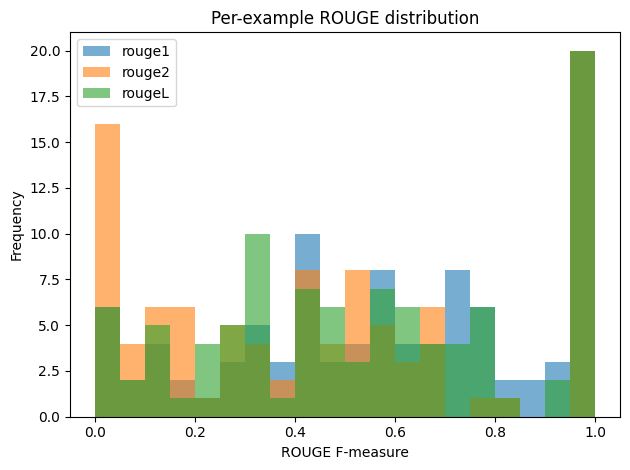

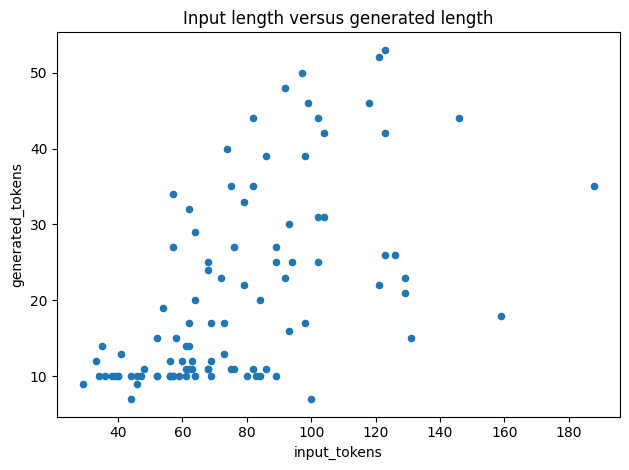

,bucket,findings,reference,prediction,rouge1,rouge2,rougeL
1,worst,"Bibasilar atelectatic changes. Otherwise, the ...","Bibasilar atelectatic changes, unchanged from ...",No acute cardiothoracic process.,0.000000,0.000000,0.000000
34,median,"Again seen are bilateral pleural effusions, ri...",Stable appearance of bilateral pleural effusio...,"Stable bilateral pleural effusions, right grea...",0.551724,0.444444,0.551724
99,best,Portable AP chest radiograph. The lungs are cl...,No acute cardiopulmonary process.,No acute cardiopulmonary process.,1.000000,1.000000,1.000000


In [7]:
if 'ev' in globals() and len(ev):
 import numpy as np
 import matplotlib.pyplot as plt
 ev[['rouge1','rouge2','rougeL']].plot.hist(bins=20,alpha=.6,title='Per-example ROUGE distribution');plt.xlabel('ROUGE F-measure');plt.tight_layout();plt.savefig(OUT/'figures/summarization_rouge_distribution.png',dpi=150);plt.show()
 ev.plot.scatter(x='input_tokens',y='generated_tokens',title='Input length versus generated length');plt.tight_layout();plt.savefig(OUT/'figures/summarization_lengths.png',dpi=150);plt.show()
 order=ev.rougeL.sort_values(); chosen=pd.concat([ev.loc[[order.index[0]]],ev.loc[[order.index[len(order)//2]]],ev.loc[[order.index[-1]]]],keys=['worst','median','best']).reset_index(level=0).rename(columns={'level_0':'bucket'});display(chosen[['bucket','findings','reference','prediction','rouge1','rouge2','rougeL']]);chosen.to_csv(OUT/'tables/summarization_best_median_worst.csv',index=False)
 review=ev.sample(n=min(20,len(ev)),random_state=42).copy();review['omission']='';review['negation_error']='';review['anatomy_laterality_error']='';review['uncertainty_error']='';review['unsupported_statement']='';review['reviewer_notes']='';review.to_csv(OUT/'tables/summarization_manual_review.csv',index=False)
else: print('Review outputs NOT RUN: no predictions available.')